# 🏠 House Price Analysis & Linear Regression

In this notebook we play the role of a small data analyst. We will:

1. **Task 1 (Data Handling):** create a house price dataset, clean it, explore it with NumPy and Pandas, and draw charts.
2. **Task 2 (Linear Regression):** teach a simple machine learning model to **predict a house's price** from its size, bedrooms and age.

**How to use this notebook**
- Run the cells from top to bottom. Click a cell and press `Shift + Enter`.
- Don't skip cells. Later cells use results from earlier ones.
- All prices are in Indian Rupees (₹). Remember: 1 lakh = ₹1,00,000 and 1 crore = ₹1,00,00,000.

# Task 1: Data Handling with NumPy and Pandas

## Step 1: Import the libraries

- **NumPy** is for numbers and arrays (lists of numbers that are fast to calculate with).
- **Pandas** is for tables of data (called DataFrames), like an Excel sheet in Python.
- **Matplotlib** is for drawing charts.

In [98]:
import numpy as np                # numbers and arrays
import pandas as pd               # tables (DataFrames)
import matplotlib.pyplot as plt   # charts

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Create a synthetic (fake) house price dataset

We don't have a real dataset, so we will **make one using random numbers**. This is called a *synthetic* dataset.
It will have 250 houses (rows) and 4 columns:

| Column | Meaning |
|---|---|
| `area` | Size of the house in square feet |
| `bedrooms` | Number of bedrooms |
| `age` | How many years old the house is |
| `price` | Price of the house in ₹ |

To make the data feel realistic, we build the price from a simple formula: **bigger houses cost more, more bedrooms cost more, older houses cost less**.
Then we add a little random "noise", because real prices are never perfectly predictable.

In [99]:
# Set a "seed" so we get the SAME random numbers every time we run the notebook.
# (Without this, the numbers would change on every run.)
np.random.seed(42)

n = 250  # number of houses (rows)

# 1) area: random whole numbers between 500 and 3000 square feet
area = np.random.randint(500, 3000, size=n)

# 2) bedrooms: bigger houses usually have more bedrooms.
#    We take area / 600, add a little randomness, round it,
#    and keep the result between 1 and 5 bedrooms.
bedrooms = np.round(area / 600 + np.random.normal(0, 0.7, size=n))
bedrooms = np.clip(bedrooms, 1, 5).astype(int)

# 3) age: random whole numbers between 0 and 30 years
age = np.random.randint(0, 31, size=n)

# 4) price: a simple formula + random noise
#    - every extra sq ft adds ₹5,000
#    - every extra bedroom adds ₹2,00,000
#    - every extra year of age removes ₹15,000
#    - the noise makes prices a little different from the perfect formula
noise = np.random.normal(0, 300000, size=n)
price = 500000 + 5000 * area + 200000 * bedrooms - 15000 * age + noise
price = price.round(0)  # round to whole rupees

# Put everything into a Pandas table (DataFrame)
df = pd.DataFrame({
    "area": area,
    "bedrooms": bedrooms,
    "age": age,
    "price": price
})

# Save to a CSV file, so we can practice "loading" data like in real projects
df.to_csv("house_data.csv", index=False)
print("Dataset created and saved as house_data.csv")

Dataset created and saved as house_data.csv


## Step 3: Load and inspect the data

Now we **load** the CSV file back into a DataFrame and look at it.

In [100]:
# Load the CSV file into a DataFrame
df = pd.read_csv("house_data.csv")

# Shape = (number of rows, number of columns)
print("Shape of the data (rows, columns):")
print(df.shape)

Shape of the data (rows, columns):
(250, 4)


In [101]:
# Data types of each column (int = whole number, float = decimal number)
print("Data types:")
print(df.dtypes)

Data types:
area          int64
bedrooms      int64
age           int64
price       float64
dtype: object


In [102]:
# head() shows the first 5 rows
df.head()

,area,bedrooms,age,price
0,1360,4,13,7709807.0
1,1794,3,8,9803862.0
2,1630,2,13,8677282.0
3,1595,3,0,8815803.0
4,2138,3,18,11534556.0


In [103]:
# describe() gives a quick summary: count, mean, std, min, quartiles, max
df.describe()

,area,bedrooms,age,price
count,250.000000,250.00000,250.000000,2.500000e+02
mean,1821.888000,3.10400,15.116000,9.978262e+06
std,686.222946,1.22441,8.899627,3.655253e+06
min,501.000000,1.00000,0.000000,2.688568e+06
25%,1263.750000,2.00000,7.000000,6.934906e+06
50%,1895.000000,3.00000,15.000000,1.048341e+07
75%,2392.250000,4.00000,23.000000,1.281608e+07
max,2989.000000,5.00000,30.000000,1.668620e+07


## Step 4: Handle missing values

Real-world data is often messy, and some values are missing (empty). If we leave them empty, calculations and models can fail or give wrong answers.

To practise, we will **randomly delete 5% of the values** in each column, and then fix them.
Since we have 250 rows, 5% is about **12 values per column**.

In Pandas, a missing value is shown as `NaN`, which stands for "Not a Number".

In [104]:
# First, check there are NO missing values right now
print("Missing values before:")
print(df.isnull().sum())

Missing values before:
area        0
bedrooms    0
age         0
price       0
dtype: int64


In [105]:
np.random.seed(0)  # seed again so the "random" deletions are the same each run

# How many values is 5% of the rows?
num_missing = int(0.05 * len(df))   # 0.05 * 250 = 12.5 -> 12
print("Values to remove per column:", num_missing)

# Go through each column one by one
for column in ["area", "bedrooms", "age", "price"]:
    # Pick 12 random row numbers (replace=False means no row is picked twice)
    random_rows = np.random.choice(df.index, size=num_missing, replace=False)

    # Set those cells to NaN (NaN means "Not a Number" = missing value)
    df.loc[random_rows, column] = np.nan
# Remember which house prices were originally missing
price_was_missing = df["price"].isna().copy()
# Check the missing values now
print("\nMissing values after removing 5%:")
print(df.isnull().sum())

Values to remove per column: 12

Missing values after removing 5%:
area        12
bedrooms    12
age         12
price       12
dtype: int64


In [106]:
# Look at a few rows that contain missing values
df[df.isnull().any(axis=1)].head()

,area,bedrooms,age,price
1,1794.0,3.0,NaN,9803862.0
11,630.0,NaN,7.0,4171617.0
12,2185.0,3.0,1.0,NaN
14,2891.0,4.0,NaN,NaN
15,2015.0,NaN,7.0,11295416.0


### Fill the missing values with the **median**

We have to decide what to put in the empty cells. Here we use the **median**.

**What is the median?** Sort all the values from smallest to largest. The median is the value **in the middle**.

**Why the median instead of the mean (average)?**

The mean can be pulled around by a few extreme values. The median cannot. Look at this tiny example of 5 house prices (in lakhs):

> 40, 45, 50, 55, **1000** (the last one is a super expensive mansion)

- **Mean** = (40 + 45 + 50 + 55 + 1000) ÷ 5 = **238 lakh**. That is much higher than almost every house, so it is a bad "typical" price.
- **Median** = the middle value = **50 lakh**. This is a much better "typical" price.

So the median is a **safe choice** because it gives a typical value even when a few houses are unusually big, small or expensive.

**Other reasons we like it here:**
- It is simple and keeps all 250 rows. (If we deleted rows with missing values, we would lose useful data.)
- For `bedrooms`, the median is usually a whole number like 3, which makes sense for a bedroom count.

**Honest note:** our fake data has no extreme outliers, so the mean and median are close here. Using the median is still a good habit, because real data often has outliers.

In [107]:
# Fill each column's missing values with that column's median
for column in ["area", "bedrooms", "age", "price"]:
    median_value = df[column].median()          # find the middle value of the column
    df[column] = df[column].fillna(median_value)  # replace NaN with that value
    print(column, "-> filled with median =", median_value)

# Make sure no missing values are left
print("\nMissing values after filling:")
print(df.isnull().sum())

area -> filled with median = 1904.0
bedrooms -> filled with median = 3.0
age -> filled with median = 14.5
price -> filled with median = 10335430.0

Missing values after filling:
area        0
bedrooms    0
age         0
price       0
dtype: int64


In [108]:
# After adding NaN, Pandas turned some whole-number columns into decimals.
# Bedrooms, area and age should be whole numbers, so we convert them back.
df["area"] = df["area"].astype(int)
df["bedrooms"] = df["bedrooms"].astype(int)
df["age"] = df["age"].astype(int)

df.dtypes

,0
area,int64
bedrooms,int64
age,int64
price,float64


## Step 5: NumPy operations

NumPy works with **arrays**: lists of numbers that can be calculated on all at once, very fast.
For example, dividing one array by another divides every pair of numbers in one step, with no loop needed.

In this step we will:
1. Convert columns to NumPy arrays
2. Calculate **price per square foot**
3. **Normalize** the area column (squeeze its values into the range 0 to 1)
4. **Filter** rows (keep only the houses that match a condition)

In [109]:
# 1) Convert columns to NumPy arrays using .values
area_array = df["area"].values
price_array = df["price"].values

print("Type of area_array:", type(area_array))
print("First 5 areas:", area_array[:5])

Type of area_array: <class 'numpy.ndarray'>
First 5 areas: [1360 1794 1630 1595 2138]


In [110]:
# 2) Price per square foot = price divided by area
#    NumPy divides the two arrays element by element (row 1 / row 1, row 2 / row 2, ...)
price_per_sqft = price_array / area_array

# Save it as a new column in our table
df["price_per_sqft"] = price_per_sqft.round(2)

print("First 5 price-per-sqft values:", price_per_sqft[:5].round(2))
print("Average price per sq ft: ₹", round(price_per_sqft.mean(), 2))

First 5 price-per-sqft values: [5668.98 5464.81 5323.49 5527.15 5395.02]
Average price per sq ft: ₹ 5543.22


In [111]:
# 3) Normalize the area column (Min-Max scaling)
#    Formula: (value - minimum) / (maximum - minimum)
#    This squeezes all values into the range 0 to 1.
area_min = area_array.min()
area_max = area_array.max()
area_normalized = (area_array - area_min) / (area_max - area_min)

df["area_normalized"] = area_normalized.round(3)

print("Smallest normalized value:", area_normalized.min())  # should be 0
print("Largest normalized value :", area_normalized.max())  # should be 1

Smallest normalized value: 0.0
Largest normalized value : 1.0


In [112]:
# 4) Filter rows: houses with 3 or more bedrooms AND area bigger than 1500 sq ft
filtered = df[(df["bedrooms"] >= 3) & (df["area"] > 1500)]

print("Number of houses that match:", len(filtered))
filtered.head()

Number of houses that match: 151


,area,bedrooms,age,price,price_per_sqft,area_normalized
1,1794,3,14,9803862.0,5464.81,0.520
3,1595,3,0,8815803.0,5527.15,0.440
4,2138,3,18,11534556.0,5395.02,0.658
5,2669,5,12,14415715.0,5401.17,0.871
9,1982,4,0,10937731.0,5518.53,0.595


## Step 6: Statistics

Statistics give us a quick summary of our data. For each column we calculate:

- **Mean:** the average value
- **Median:** the middle value
- **Std (standard deviation):** how spread out the values are. A small std means values are close together, and a big std means they are far apart.
- **Min / Max:** the smallest and the largest value

In [113]:
# Mean, median, standard deviation, minimum and maximum for each main column
stats = df[["area", "bedrooms", "age", "price"]].agg(["mean", "median", "std", "min", "max"])
stats.round(2)

,area,bedrooms,age,price
mean,1824.21,3.07,14.78,9972405.78
median,1904.00,3.00,14.00,10335430.00
std,674.46,1.19,8.65,3568985.65
min,501.00,1.00,0.00,2688568.00
max,2989.00,5.00,30.00,16686198.00


**Quick meaning of each statistic:**

- **Mean** = the average
- **Median** = the middle value
- **Std** (standard deviation) = how spread out the values are (bigger = more spread)
- **Min / Max** = the smallest / largest value

In [114]:
# Correlation between area, bedrooms and price
# Correlation is a number from -1 to +1:
#   close to +1 -> when one goes up, the other goes up
#   close to  0 -> no clear relationship
#   close to -1 -> when one goes up, the other goes down
correlation = df[["area", "bedrooms", "price"]].corr()
correlation.round(3)

,area,bedrooms,price
area,1.000,0.795,0.954
bedrooms,0.795,1.000,0.798
price,0.954,0.798,1.000


## Step 7: Groupby: average price by number of bedrooms

`groupby` splits the table into groups (here, one group for each bedroom count: 1, 2, 3, 4, 5) and then calculates something for each group.

Here we ask: *"What is the average price of 1-bedroom houses? 2-bedroom houses? And so on."*

In [115]:
# Average price for each number of bedrooms
avg_price_by_bedrooms = df.groupby("bedrooms")["price"].mean().round(0)
avg_price_by_bedrooms

,price
bedrooms,
1,4955891.0
2,7402208.0
3,9793469.0
4,12292524.0
5,14462995.0


## Step 8: Charts

A picture can show things that numbers hide.

- The **histogram** shows how prices are spread: how many houses fall into each price range.
- The **scatter plot** shows the relationship between two things. Each dot is one house, with its area on the x-axis and its price on the y-axis.

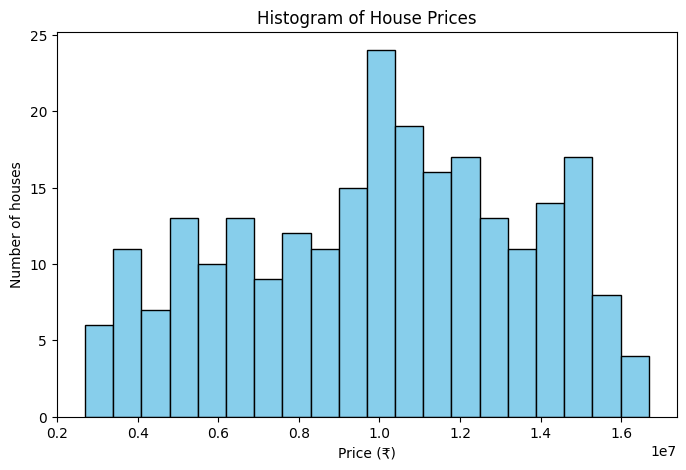

In [116]:
# Histogram of price: shows how many houses fall in each price range
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=20, color="skyblue", edgecolor="black")
plt.title("Histogram of House Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of houses")
plt.show()

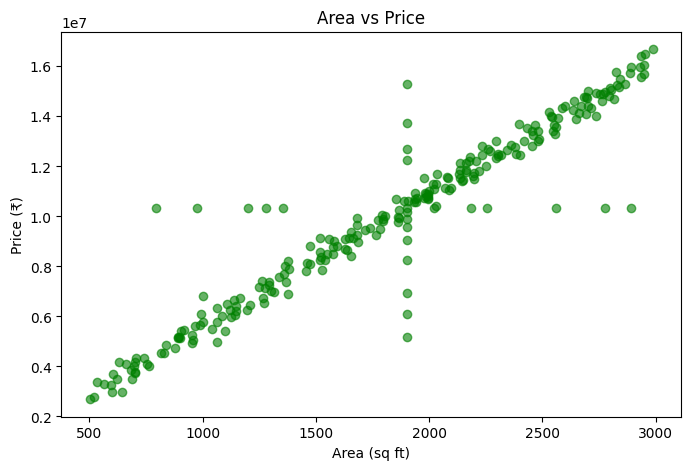

In [117]:
# Scatter plot: each dot is one house (area on x-axis, price on y-axis)
plt.figure(figsize=(8, 5))
plt.scatter(df["area"], df["price"], color="green", alpha=0.6)
plt.title("Area vs Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (₹)")
plt.show()

## Step 9: Observations

What did we learn from the numbers and charts?

1. **Bigger houses cost more, and area matters the most.** The correlation between area and price is about **0.95**, which is very close to 1. (Correlation near +1 means "when one goes up, the other goes up too".) In the scatter plot, the dots rise in an almost straight line from bottom-left to top-right.

2. **Each extra bedroom adds roughly ₹24 lakh to the average price.** The average price goes from about ₹50 lakh for 1-bedroom houses to about ₹1.45 crore for 5-bedroom houses, and it rises steadily at every step.

3. **Bedrooms and area go together.** Bigger houses tend to have more bedrooms (correlation about **0.80**). So part of the "bedroom effect" on price is really the "area effect" in disguise.

4. **Age matters very little in our data.** The correlation between age and price is only about **-0.10**. The small minus sign means older houses are slightly cheaper, but the effect is weak compared to area and bedrooms.

*Bonus: the prices are spread widely, from about ₹27 lakh to ₹1.67 crore, and the histogram has no extreme outliers.*

---
# Task 2: Linear Regression

**The idea:** Linear Regression looks at old houses (where we know the size, bedrooms, age **and** the price) and finds the **best straight-line pattern** between them.
Once it has learned this pattern, we can give it a *new* house and it will **predict the price**.

Two words to remember:
- **Features** are the things we know about a house: `area`, `bedrooms`, `age`. (Also called inputs or **X**.)
- **Target** is the thing we want to predict: `price`. (Also called the output or **y**.)

## Step 1: Import the machine learning tools

We use **scikit-learn** (written `sklearn`), a very popular and beginner-friendly machine learning library.
From it we import a tool to split data, the Linear Regression model, and some scoring functions.

In [118]:
from sklearn.model_selection import train_test_split   # splits data into train and test parts
from sklearn.linear_model import LinearRegression      # the model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # score functions

print("Machine learning tools imported!")

Machine learning tools imported!


## Step 2: Choose the features (X) and target (y)

- **X** = the inputs (features): `area`, `bedrooms`, `age`
- **y** = the output we want to predict: `price`

We use the **cleaned data** from Task 1 (missing values already filled).

In [119]:
X = df[["area", "bedrooms", "age"]]   # features
y = df["price"]                       # target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250, 3)
y shape: (250,)


## Step 3: Split into training and testing data (80/20)

We cannot test the model on the same houses it learned from. That would be like giving a student the exact exam questions in advance, so a good score would prove nothing.

So we split the data into two parts:
- **Training set (80%, 200 houses):** the model **learns** from these.
- **Test set (20%, 50 houses):** the model has **never seen** these. We use them as a fair exam to check how good the model really is.

In [120]:
# test_size=0.2 means 20% of the data is for testing
# random_state=42 makes the split the same every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training houses:", len(X_train))
print("Testing houses :", len(X_test))

Training houses: 200
Testing houses : 50


## Step 4: Train the Linear Regression model

In [121]:
# Create an empty model
model = LinearRegression()

# fit() = train the model: it learns the relationship between X_train and y_train
model.fit(X_train, y_train)

print("Model trained!")

Model trained!


## Step 5: Coefficients and intercept

After training, the model gives us a few numbers that describe the pattern it found.

In [122]:
# Intercept = the starting price when all features are 0
print("Intercept: ₹", round(model.intercept_, 2))

# Coefficients = how much the price changes when a feature goes up by 1
feature_names = ["area", "bedrooms", "age"]
for name, coef in zip(feature_names, model.coef_):
    print(name, "coefficient: ₹", round(coef, 2))

Intercept: ₹ 605962.92
area coefficient: ₹ 4493.69
bedrooms coefficient: ₹ 404029.15
age coefficient: ₹ -8444.37


### What do these numbers mean in plain English?

The model works like a price calculator with this formula:

**price = intercept + (area coefficient × area) + (bedrooms coefficient × bedrooms) + (age coefficient × age)**

**Coefficient** = *"how much the price changes when this one thing goes up by 1, while the other things stay the same."*

With the settings in this notebook (seed 42), the model found roughly these numbers:

| Number | Value (approx.) | Plain English meaning |
|---|---|---|
| **Area coefficient** | about **+₹4,494** | Every extra **1 sq ft** adds about ₹4,494 to the price. So **100 extra sq ft ≈ ₹4.5 lakh more**. |
| **Bedrooms coefficient** | about **+₹4.04 lakh** | Every extra **bedroom** adds about ₹4 lakh to the price (same area and age). |
| **Age coefficient** | about **−₹8,444** | Every extra **year of age** *reduces* the price by about ₹8,444. A **minus sign means "price goes down"**. |
| **Intercept** | about **₹6.06 lakh** | The starting number in the formula, used when area, bedrooms and age are all 0. There is no such house, so it is just the **starting point of the line**. Don't worry if it looks strange. |

**Let's check by hand** with our new house (1200 sq ft, 3 bedrooms, 10 years old):

6,05,963 + (4,494 × 1200) + (4,04,029 × 3) − (8,444 × 10) ≈ **₹71.3 lakh**

This matches the prediction we make in Step 7, so you can see there is no magic: the model is just using this formula.

**Why are the numbers not exactly the ones we used to create the data?**
We created the data with ₹5,000 per sq ft, ₹2 lakh per bedroom and −₹15,000 per year of age. The model's numbers are in the same direction and the same general size, but not identical. This happens because:
- we added random noise to the prices,
- 5% of values were replaced with medians in Task 1, which blurs the pattern a little, and
- area and bedrooms move together (bigger houses have more bedrooms), so the model shares their combined effect between the two. That is why the bedroom number looks bigger than ₹2 lakh.

## Step 6: Make predictions on the test data and measure the errors

In [123]:
# Predict prices for the test houses (houses the model has never seen)
y_pred = model.predict(X_test)

# MAE: Mean Absolute Error = average size of the mistakes
mae = mean_absolute_error(y_test, y_pred)

# RMSE: Root Mean Squared Error = like MAE, but big mistakes are punished more
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# R2: how much of the price variation the model explains (1.0 = perfect)
r2 = r2_score(y_test, y_pred)

print("MAE : ₹", round(mae, 2))
print("RMSE: ₹", round(rmse, 2))
print("R²  :", round(r2, 4))

MAE : ₹ 447693.09
RMSE: ₹ 877894.12
R²  : 0.9348


### What do these scores mean?

These three scores tell us **how good the predictions are** on the 50 test houses the model never saw.
They are calculated by looking at the **error** of each prediction: the gap between the actual price and the predicted price.

**1. MAE: Mean Absolute Error** *(lower is better)*
- **Meaning:** On average, how many rupees is the prediction off by?
- **How it works:** Take each error, ignore whether it is above or below the real price, and average them.
- **Example:** an MAE of about ₹4.5 lakh means the model's price is typically off by around ₹4.5 lakh. Since the average house costs about ₹1 crore, that is a small mistake.
- Think of it as the **average distance by which you miss the target in a dart game**.

**2. RMSE: Root Mean Squared Error** *(lower is better)*
- **Meaning:** Similar to MAE, but **big mistakes are punished much more** than small ones.
- **How to read it:** RMSE is always equal to or bigger than MAE.
  - If RMSE is **close to** MAE, the errors are all of similar size.
  - If RMSE is **much bigger** than MAE, a few predictions are very wrong.
- **In our notebook:** RMSE (about ₹8.8 lakh) is nearly double MAE (about ₹4.5 lakh). That is because some houses had their price replaced by the median in Task 1. Those rows do not follow the real pattern, so the model badly misses them.

**3. R²: R-squared** *(closer to 1 is better)*
- **Meaning:** What fraction of the ups and downs in price does the model explain?
- **Scale:** 1.0 means a perfect model, 0 means the model is no better than always guessing the average price, and a negative value means it is worse than that.
- **Example:** an R² of about 0.93 means the model explains **about 93%** of why house prices differ. The other 7% is noise or things the model can't see.
- Think of it as the model's **exam score out of 100%**.

**Tip:** MAE and RMSE are in rupees, so they are easy to picture. R² is a percentage-style score, so it is good for a quick "how good is this model overall?" check.

## Step 7: Predict the price of a new house

Now the useful part: giving the trained model a **brand new house** and asking for its price.

New house: **1200 sq ft, 3 bedrooms**.

The model was trained with `age` too, so we must give it an age. We will assume the house is **10 years old** (you can change this number).

In [124]:
# Create a table with one row for the new house.
# The column names must be the same as the ones used for training.
new_house = pd.DataFrame({
    "area": [1200],
    "bedrooms": [3],
    "age": [10]      # we assume 10 years old
})

predicted_price = model.predict(new_house)

print("Predicted price for a 1200 sq ft, 3 bedroom, 10 year old house:")
print("₹", round(predicted_price[0], 2))

Predicted price for a 1200 sq ft, 3 bedroom, 10 year old house:
₹ 7126030.72


## Step 8: Plot actual vs predicted prices

This chart is a quick visual check of the model. Each dot is one house from the test set:
- **x-axis:** the house's real (actual) price
- **y-axis:** the price our model predicted

**How to read it:** the red dashed line is the "perfect prediction" line, where predicted price equals actual price.
- Dots **close to the line** → good predictions
- Dots **far from the line** → big mistakes

In our chart, most dots hug the line, which matches the high R² score. A few dots are far away. Those are the houses whose prices were filled with the median earlier.

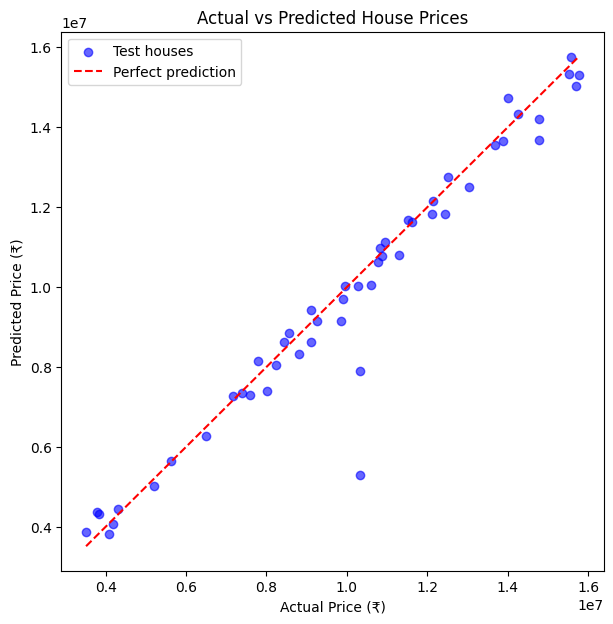

In [125]:
plt.figure(figsize=(7, 7))

# Each dot: x = actual price, y = predicted price
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, label="Test houses")

# Draw the "perfect prediction" line
lowest = min(y_test.min(), y_pred.min())
highest = max(y_test.max(), y_pred.max())
plt.plot([lowest, highest], [lowest, highest], color="red", linestyle="--", label="Perfect prediction")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.legend()
plt.show()

## 🎉 Summary

- **Task 1:** We created a house dataset, handled missing values with the median, used NumPy and Pandas to explore it, and drew charts. We found that **area is the biggest factor in price**.
- **Task 2:** We trained a Linear Regression model that predicts price from area, bedrooms and age, and we checked it on houses it had never seen.
- **Scores:** MAE and RMSE tell us the typical error in rupees, and R² tells us how much of the price variation the model explains.
- **Prediction:** We used the model to estimate the price of a new house.

**Ideas to try next:**
- Change `n` from 250 to 1000 rows and see how the scores change.
- Remove `age` from the features and check whether R² goes up or down.
- Change `test_size` from `0.2` to `0.3`.
- Try dropping the rows with missing values instead of filling them, and compare RMSE.